# Experiment 5

### Name - Mohisha Punwatkar
### Class - B (B1)
### Roll No - 12

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, GridSearchCV , cross_val_score,StratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score, f1_score,confusion_matrix, classification_report,
                            roc_curve,roc_auc_score)
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

In [6]:
df = pd.read_csv("/content/diabetes (6).csv")
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [7]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [11]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [12]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [14]:
pd.set_option('display.float_format', '{:.2f}'.format)


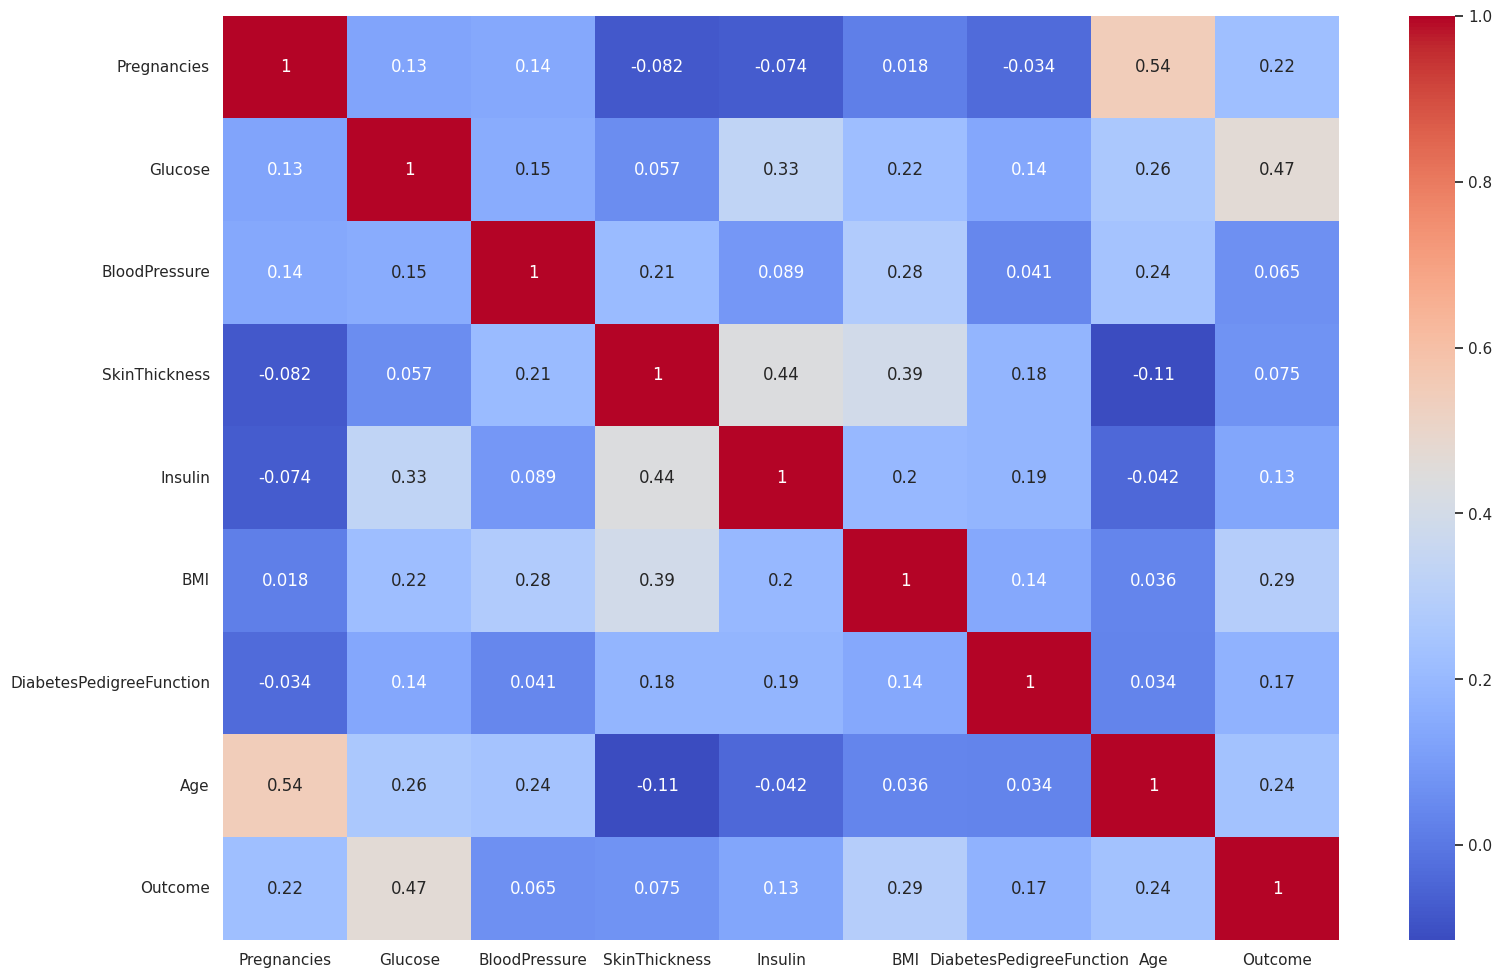

In [16]:
plt.figure(figsize=(18, 12))

numeric_df = df.select_dtypes(include=["number"])

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.show()

In [23]:
Q1 = df["Glucose"].quantile(0.25)
Q3 = df["Glucose"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[
    (df["Glucose"] >= lower) &
    (df["Glucose"] <= upper)
]

print("Shape after removing outliers:", df.shape)

Shape after removing outliers: (763, 9)


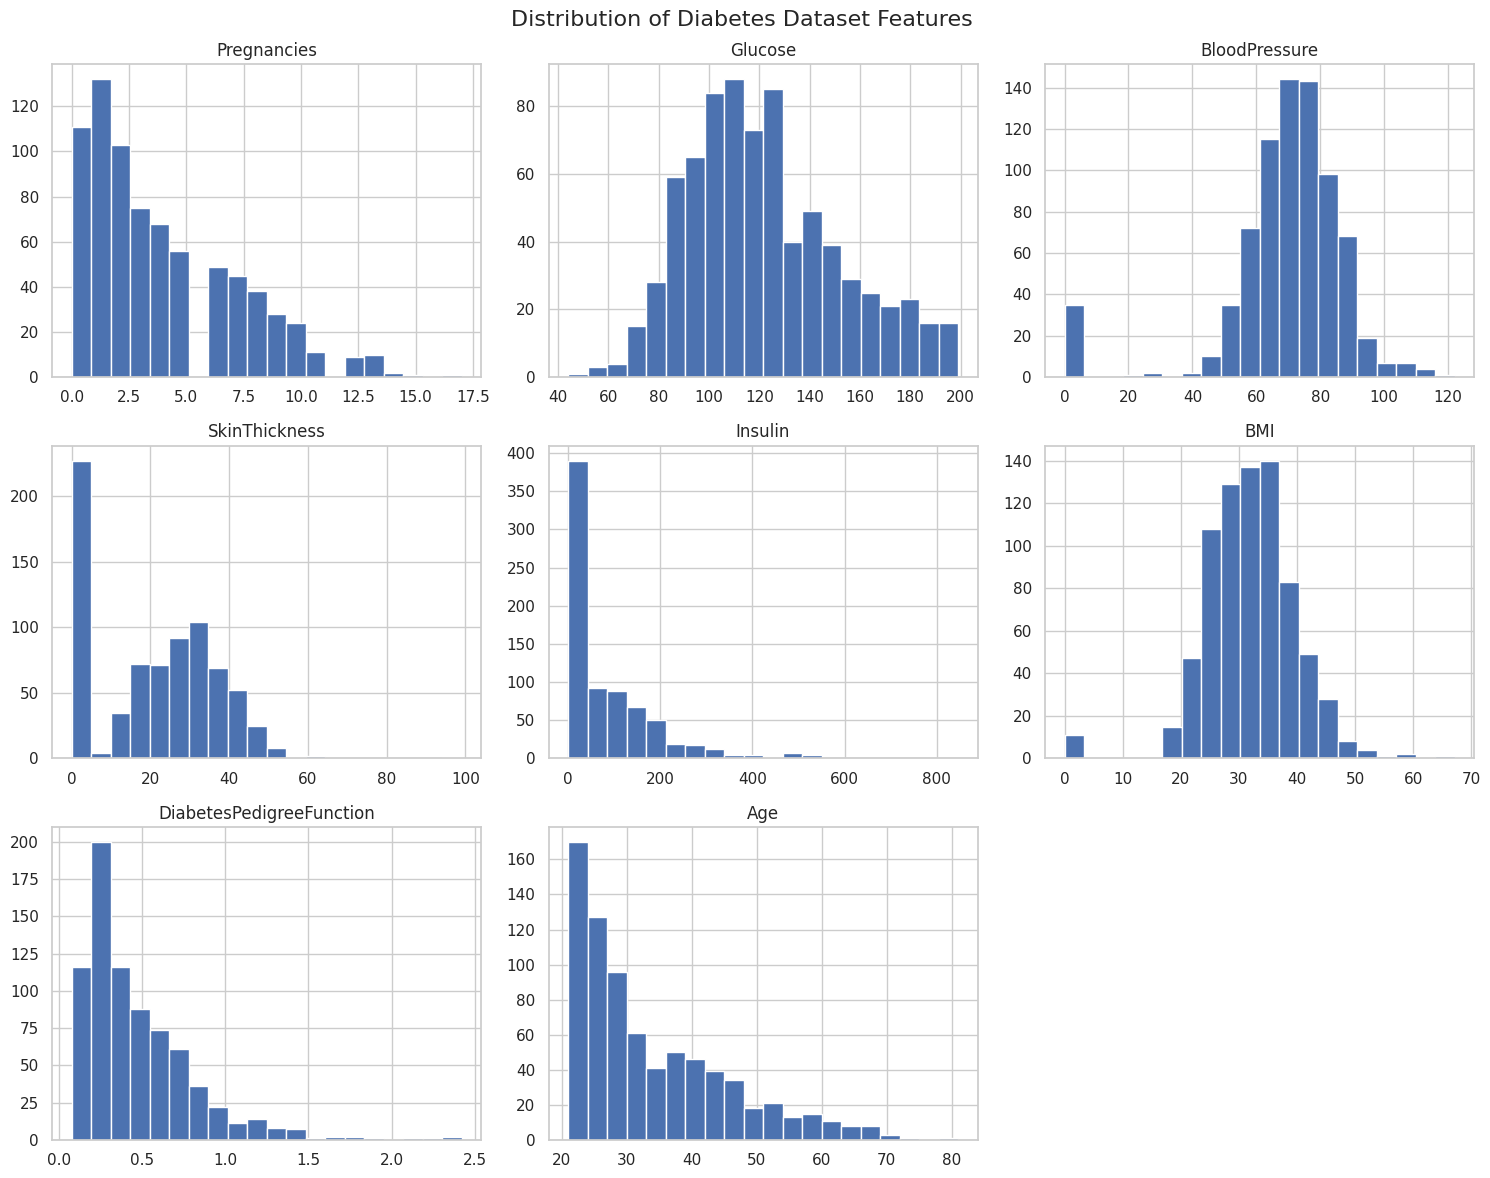

In [25]:
features = df.drop(columns="Outcome").columns

df[features].hist(figsize=(15, 12), bins=20)

plt.suptitle("Distribution of Diabetes Dataset Features", fontsize=16)
plt.tight_layout()
plt.show()

In [26]:
zero_columns=["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
zero_counts= (df[zero_columns]==0).sum()
print(zero_counts)

Glucose            0
BloodPressure     35
SkinThickness    227
Insulin          370
BMI               11
dtype: int64


In [27]:
df_clean = df.copy()
df_clean[zero_columns] = df_clean[zero_columns].replace(0,np.nan)
print("Missing values after replacing invalud zeroes:")
print(df_clean.isnull().sum())

Missing values after replacing invalud zeroes:
Pregnancies                   0
Glucose                       0
BloodPressure                35
SkinThickness               227
Insulin                     370
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [29]:
for col in zero_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())
    print("Missing values after median imputation:")
    print(df_clean.isnull().sum())

Missing values after median imputation:
Pregnancies                   0
Glucose                       0
BloodPressure                35
SkinThickness               227
Insulin                     370
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64
Missing values after median imputation:
Pregnancies                   0
Glucose                       0
BloodPressure                 0
SkinThickness               227
Insulin                     370
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64
Missing values after median imputation:
Pregnancies                   0
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                     370
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome               

In [31]:
X = df_clean.drop("Outcome", axis=1)
y = df_clean["Outcome"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (763, 8)
y shape: (763,)


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 610
Testing samples: 153


In [35]:
print("Training distribution:")
print(y_train.value_counts(normalize=True))
print("\Testing distribution:")
print(y_test.value_counts(normalize=True))

Training distribution:
Outcome
0   0.65
1   0.35
Name: proportion, dtype: float64
\Testing distribution:
Outcome
0   0.65
1   0.35
Name: proportion, dtype: float64


In [36]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [37]:
scaler.fit_transform(X_test)

array([[ 0.07246271,  1.67186008, -0.04884218, ...,  1.96762681,
         0.14679139, -0.65947541],
       [-0.82646654,  0.36986402, -0.22063191, ..., -1.04812404,
         0.12124067, -1.00064105],
       [ 0.37210579,  1.57659207, -0.73600111, ...,  0.14454579,
        -1.10884399,  0.61989574],
       ...,
       [-0.52682346, -1.18618006, -1.07958057, ..., -0.74143751,
        -0.54307805, -0.74476682],
       [-0.22718038,  1.73537208,  0.46652702, ...,  0.29788906,
         1.93899189, -0.23301836],
       [-1.12610963, -1.94832409, -1.07958057, ..., -1.76372593,
         1.08121772,  2.8374724 ]])

In [38]:
scaler.transform(X_test)

array([[ 0.07246271,  1.67186008, -0.04884218, ...,  1.96762681,
         0.14679139, -0.65947541],
       [-0.82646654,  0.36986402, -0.22063191, ..., -1.04812404,
         0.12124067, -1.00064105],
       [ 0.37210579,  1.57659207, -0.73600111, ...,  0.14454579,
        -1.10884399,  0.61989574],
       ...,
       [-0.52682346, -1.18618006, -1.07958057, ..., -0.74143751,
        -0.54307805, -0.74476682],
       [-0.22718038,  1.73537208,  0.46652702, ...,  0.29788906,
         1.93899189, -0.23301836],
       [-1.12610963, -1.94832409, -1.07958057, ..., -1.76372593,
         1.08121772,  2.8374724 ]])

In [40]:
comparison = pd.DataFrame({
    "original mean": X_train.mean(),
    "original Std" : X_train.std(),
    "Scaled Mean" : X_train_scaled.mean(axis=0),
    "Scaled Std" : X_train_scaled.std(axis=0)
})
display(comparison)

,original mean,original Std,Scaled Mean,Scaled Std
Pregnancies,3.88,3.38,-0.00,1.00
Glucose,122.52,30.23,-0.00,1.00
BloodPressure,72.38,12.21,-0.00,1.00
SkinThickness,29.27,8.95,0.00,1.00
Insulin,140.94,83.30,-0.00,1.00
BMI,32.55,7.11,0.00,1.00
DiabetesPedigreeFunction,0.48,0.34,0.00,1.00
Age,33.16,11.78,0.00,1.00


In [41]:
K=5

In [43]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [44]:
y_pred = knn.predict(X_test_scaled)
print("Predictions:")
print(y_pred[:20])

Predictions:
[1 0 1 0 0 0 0 1 0 1 1 0 0 1 1 0 1 1 1 0]


In [46]:
y_prob = knn.predict_proba(X_test_scaled)[:, 1]
print(y_prob[:20])

[0.8 0.2 0.6 0.4 0.2 0.  0.  0.8 0.  0.8 0.8 0.  0.2 0.8 0.6 0.4 1.  0.6
 0.6 0.4]


In [47]:
accuracy = accuracy_score(y_test,y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.7451


In [48]:
precision = precision_score(y_test,y_pred)
print(f"Precision:{precision:.4f}")

Precision:0.6667


In [51]:
recall= recall_score(y_test,y_pred)
print(f"Recall: {recall:.4f}")

Recall: 0.5283


In [52]:
f1 = f1_score(y_test,y_pred)
print(f"F1 Score: {f1:.4f}")

F1 Score: 0.5895


In [53]:
print(classification_report(y_test,y_pred,target_names=["No Diabetes","Diabetes"]))

              precision    recall  f1-score   support

 No Diabetes       0.77      0.86      0.82       100
    Diabetes       0.67      0.53      0.59        53

    accuracy                           0.75       153
   macro avg       0.72      0.69      0.70       153
weighted avg       0.74      0.75      0.74       153



In [54]:
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[86 14]
 [25 28]]


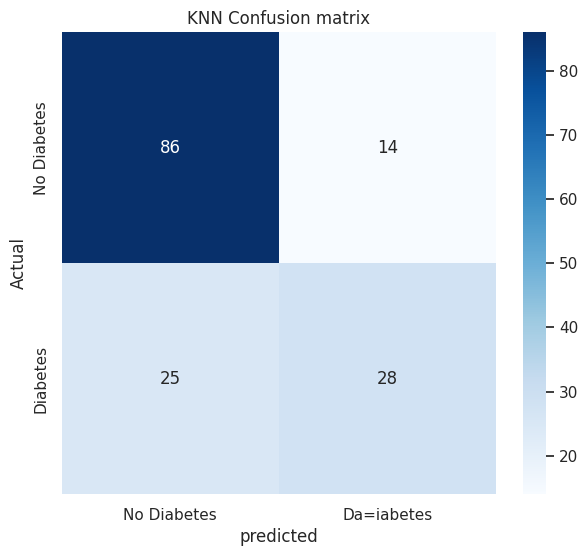

In [55]:
plt.figure(figsize=(7,6))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["No Diabetes","Da=iabetes"],
           yticklabels=["No Diabetes","Diabetes"])
plt.xlabel("predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion matrix")
plt.show()

In [57]:
k_values = range(1, 31)
train_accuracy = []
test_accuracy = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)

    train_accuracy.append(model.score(X_train_scaled, y_train))
    test_accuracy.append(model.score(X_test_scaled, y_test))

Text(0.5, 0, 'Number')

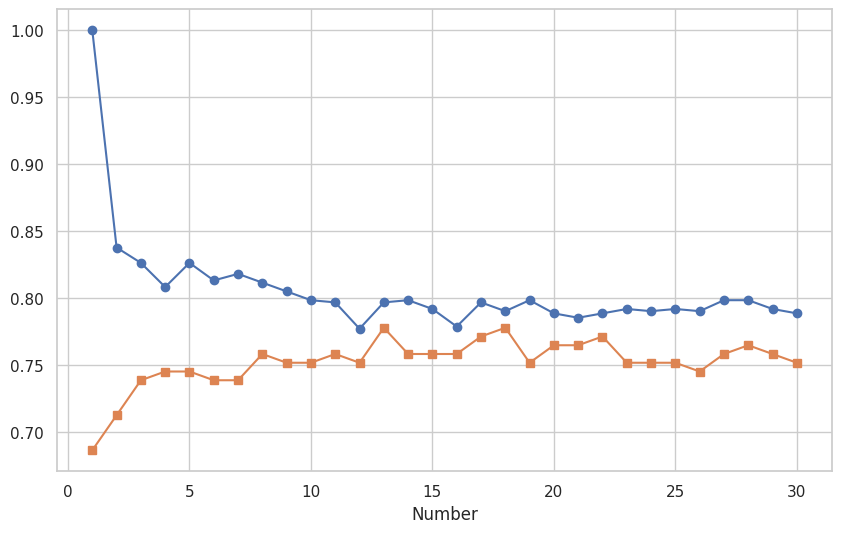

In [58]:
plt.figure(figsize=(10,6))
plt.plot(k_values,train_accuracy,marker="o",label="Training Accuracy")
plt.plot(k_values,test_accuracy,marker="s",label="Testing Accuracy")
plt.xlabel("Number")

In [59]:
best_k_accuracy= k_values[np.argmax(test_accuracy)]
best_accuracy = max(test_accuracy)
print("best K:", best_k_accuracy)
print("best test accuracy:",best_accuracy)

best K: 13
best test accuracy: 0.7777777777777778


In [61]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = []

for k in range(1, 31):
    model = KNeighborsClassifier(n_neighbors=k)

    scores = cross_val_score(
        model,
        X_train_scaled,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    cv_scores.append(scores.mean())

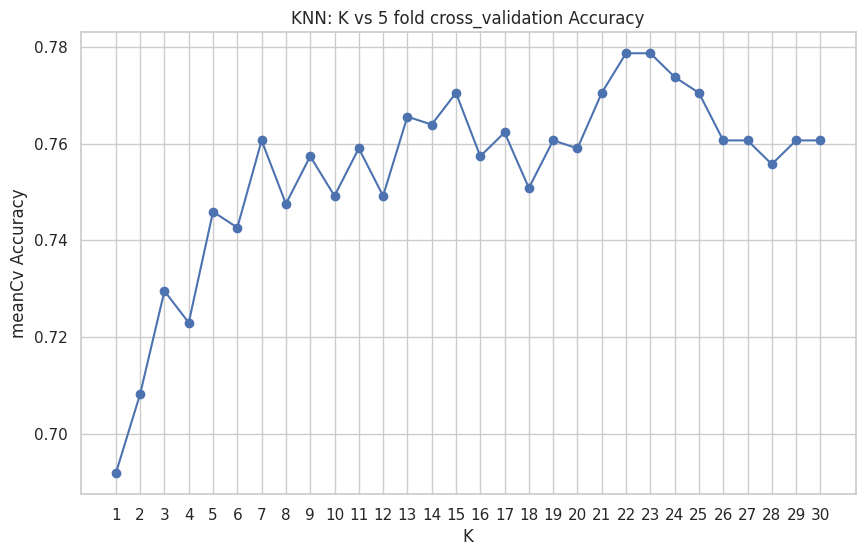

In [62]:
plt.figure(figsize=(10,6))
plt.plot(range(1,31),cv_scores,marker="o")
plt.xlabel("K")
plt.ylabel("meanCv Accuracy")
plt.title("KNN: K vs 5 fold cross_validation Accuracy")
plt.xticks(range(1,31))
plt.show()

In [63]:
best_k_cv =np.argmax(cv_scores)+1
print("best k based on cross validation:", best_k_cv)
print("best CV Accuracy:", max(cv_scores))

best k based on cross validation: 22
best CV Accuracy: 0.7786885245901639


In [64]:
param_grid = {"n_neighbours": list(range(3,31,2)),"weights": ["uniform","distance"],
             "metric": ["euclidean","manhattan","minkowski"],"p": [1,2]
             }

In [69]:
param_grid = {
    "n_neighbors": range(1, 31),
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"]
}

grid_search = GridSearchCV(estimator=KNeighborsClassifier(), param_grid=param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)
print("Grid search completed.")

Grid search completed.


In [70]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'metric': 'euclidean', 'n_neighbors': 15, 'weights': 'uniform'}


In [71]:
print("Best Cross-validation Accuracy:",grid_search.best_score_)

Best Cross-validation Accuracy: 0.7721311475409837
